
# **Arabic Readability Classification Using Decision Tree**

## **Experiment Objective**

The objective of this experiment is to evaluate the Decision Tree classifier for Arabic readability classification using the BAREC Corpus.

The experiment uses TF-IDF for feature extraction and Decision Tree as the classification algorithm. It investigates baseline performance, hyperparameter tuning, and the effect of class weighting.

The experiment also compares 19-level, 5-level, and 4-level classification setups to examine how the number of readability levels affects model performance.





## **Why Decision Tree?**

Decision Tree is a supervised machine learning algorithm used for classification tasks. It can handle high-dimensional features, such as those generated by TF-IDF representations of text. Decision Tree works by learning decision rules that split the data based on important features to classify text into different categories. It is also simple to understand and interpret, making it useful for analyzing classification decisions. In addition, Decision Tree supports multi-class classification and allows hyperparameter tuning to control model complexity, making it suitable for Arabic readability classification across multiple readability levels.





## 1. **Data Loading**

This section loads the preprocessed BAREC datasets for the original and four-level classification setups. Each setup contains separate training, development, and test sets.

The existing data splits are preserved without additional preprocessing or resampling. The dataset structure, column names, and sample counts are inspected before proceeding to feature extraction.

In [53]:

from google.colab import files
import zipfile
import os
from pathlib import Path
import numpy as np
import pandas as pd

# Upload and extract BAREC dataset
uploaded = files.upload()
zip_path = next(iter(uploaded))

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

# Find dataset folder
folders = [
    p.parent for p in Path("/content").rglob("original")
    if p.is_dir() and (p.parent / "merged_4_level").is_dir()
]

if not folders:
    raise FileNotFoundError("BAREC dataset folders not found.")

data_dir = str(folders[0])
original_dir = os.path.join(data_dir, "original")
merged_dir = os.path.join(data_dir, "merged_4_level")

# Load original dataset splits
train_original = pd.read_csv(os.path.join(original_dir, "train.csv"))
dev_original = pd.read_csv(os.path.join(original_dir, "dev.csv"))
test_original = pd.read_csv(os.path.join(original_dir, "test.csv"))

# Load four-level dataset splits
train_4level = pd.read_csv(os.path.join(merged_dir, "train.csv"))
dev_4level = pd.read_csv(os.path.join(merged_dir, "dev.csv"))
test_4level = pd.read_csv(os.path.join(merged_dir, "test.csv"))

datasets = {
    "Original - Train": train_original,
    "Original - Dev": dev_original,
    "Original - Test": test_original,
    "Four-Level - Train": train_4level,
    "Four-Level - Dev": dev_4level,
    "Four-Level - Test": test_4level
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

# Input text
dt_X_train = train_original["Word"].fillna("").astype(str)
dt_X_dev = dev_original["Word"].fillna("").astype(str)
dt_X_test = test_original["Word"].fillna("").astype(str)

# 19-level labels
dt_y_train_19 = train_original["Readability_Level_19"]
dt_y_dev_19 = dev_original["Readability_Level_19"]
dt_y_test_19 = test_original["Readability_Level_19"]

# 5-level labels
dt_y_train_5 = train_original["Readability_Level_5"]
dt_y_dev_5 = dev_original["Readability_Level_5"]
dt_y_test_5 = test_original["Readability_Level_5"]

# 4-level labels
dt_y_train_4 = train_4level["Readability_Level_4"]
dt_y_dev_4 = dev_4level["Readability_Level_4"]
dt_y_test_4 = test_4level["Readability_Level_4"]


Saving BAREC_prepared_datasets.zip to BAREC_prepared_datasets (3).zip

Original - Train
Shape: (54845, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Original - Dev
Shape: (7310, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Original - Test
Shape: (7286, 19)
Columns: ['ID', 'Sentence', 'Word_Count', 'Word', 'Lex', 'D3Tok', 'D3Lex', 'Readability_Level', 'Readability_Level_19', 'Readability_Level_7', 'Readability_Level_5', 'Readability_Level_3', 'Annotator', 'Document', 'Source', 'Book', 'Author', 'Domain', 'Text_Class']

Four-Level - Train
Shape:


## 2. **Feature Extraction Using TF-IDF**

The Word column is used as the input text representation for the Decision Tree classifier.

TF-IDF (Term Frequency–Inverse Document Frequency) converts Arabic text into numerical feature vectors. Both unigrams and bigrams are included to capture individual words and consecutive word pairs.

The vectorizer is fitted exclusively on the training set and then applied to the development and test sets to prevent information leakage.


In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer

dt_vectorizer = TfidfVectorizer(ngram_range=(1, 2))

dt_X_train_tfidf = dt_vectorizer.fit_transform(dt_X_train)
dt_X_dev_tfidf = dt_vectorizer.transform(dt_X_dev)
dt_X_test_tfidf = dt_vectorizer.transform(dt_X_test)

print("Training TF-IDF shape:", dt_X_train_tfidf.shape)
print("Development TF-IDF shape:", dt_X_dev_tfidf.shape)
print("Test TF-IDF shape:", dt_X_test_tfidf.shape)
print("Vocabulary size:", len(dt_vectorizer.vocabulary_))


Training TF-IDF shape: (54845, 520826)
Development TF-IDF shape: (7310, 520826)
Test TF-IDF shape: (7286, 520826)
Vocabulary size: 520826



## **3. Model Evaluation**



### 3.1 Evaluation Metrics Overview

The Decision Tree models are evaluated using classification and ordinal metrics.

- **Quadratic Weighted Kappa (QWK):** Measures agreement between actual and predicted readability levels while penalizing larger errors more heavily.
- **Accuracy:** Measures the proportion of correctly classified samples.
- **Adjacent Accuracy (±1):** Considers predictions correct when they differ from the actual level by no more than one.
- **Macro F1-score:** Gives equal importance to all classes.
- **Weighted Precision:** Measures precision while accounting for class support.
- **Weighted Recall:** Measures recall while accounting for class support.
- **Mean Absolute Error (MAE):** Measures the average absolute prediction error.
- **Root Mean Squared Error (RMSE):** Penalizes larger prediction errors more heavily.
- **R² Score:** Measures explained variance when readability labels are treated numerically.
- **Confusion Matrix:** Visualizes correct predictions and misclassification patterns.



### 3.2 Evaluation Function

A reusable evaluation function is implemented to ensure consistent performance assessment across the 19-level, 5-level, and 4-level Decision Tree experiments.



In [55]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    cohen_kappa_score,
    r2_score,
    confusion_matrix
)

def evaluate_dt_model(y_true, y_pred, dataset_name):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Adjacent Accuracy (±1)": np.mean(
            np.abs(y_true - y_pred) <= 1
        ),
        "QWK": cohen_kappa_score(
            y_true, y_pred, weights="quadratic"
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Weighted Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Weighted Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }

    print("=" * 60)
    print(dataset_name)
    print("=" * 60)

    for name, value in metrics.items():
        print(f"{name}: {value:.4f}")

    print("\nClassification Report:\n")
    print(classification_report(
        y_true, y_pred, zero_division=0
    ))

    return metrics




### 3.3 Confusion Matrix Visualization

A reusable confusion matrix function is implemented to visualize classification performance and identify common misclassification patterns between readability levels.


In [56]:

def plot_dt_confusion_matrix(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()



## **4. Decision Tree (19-Level)**



### 4.1 Decision Tree Baseline (19-Level)

A baseline Decision Tree classifier is trained using default hyperparameters to establish a reference point for the 19-level Arabic readability classification task.

The model uses Word + TF-IDF features. Its default parameters are displayed before training.

The baseline results serve as a reference for subsequent hyperparameter tuning experiments.


{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
Baseline Decision Tree (19-Level) - Dev Set
Accuracy: 0.2858
Adjacent Accuracy (±1): 0.4140
QWK: 0.3550
Macro F1: 0.2207
Weighted Precision: 0.2938
Weighted Recall: 0.2858
MAE: 2.6369
RMSE: 3.7483
R²: -0.2359

Classification Report:

              precision    recall  f1-score   support

           1       0.45      0.68      0.54        44
           2       0.22      0.22      0.22        68
           3       0.36      0.39      0.37       182
           4       0.13      0.29      0.18        78
           5       0.39      0.45      0.42       417
           6       0.31      0.28      0.29       189
           7       0.29      0.31      0.30       701
           8       0.28      0.41

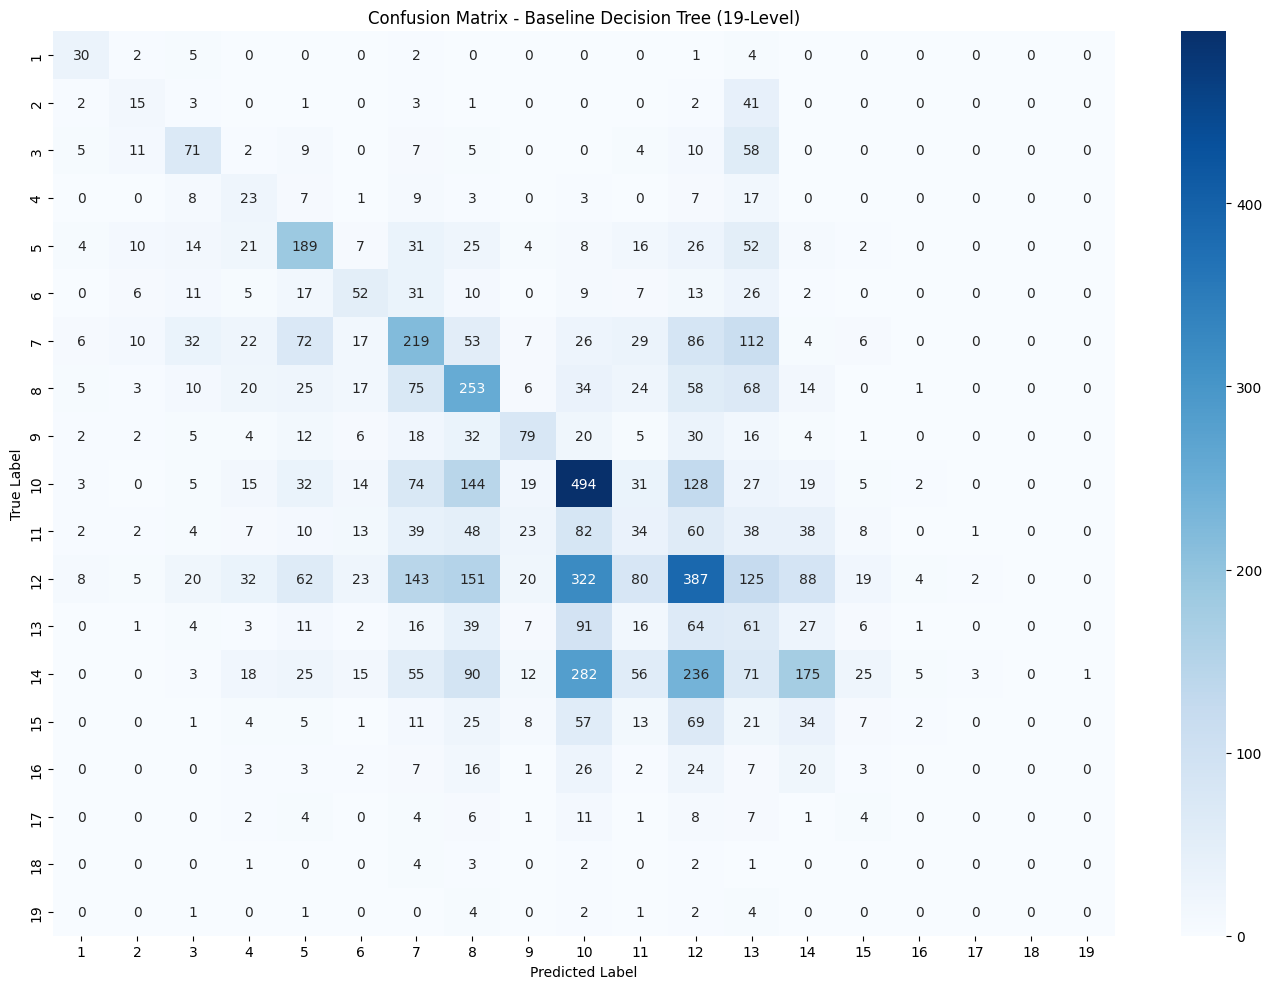

In [57]:

from sklearn.tree import DecisionTreeClassifier

dt_baseline_19 = DecisionTreeClassifier(random_state=42)

print(dt_baseline_19.get_params())

dt_baseline_19.fit(
    dt_X_train_tfidf,
    dt_y_train_19
)

dt_baseline_19_dev_pred = dt_baseline_19.predict(
    dt_X_dev_tfidf
)

dt_baseline_19_metrics = evaluate_dt_model(
    dt_y_dev_19,
    dt_baseline_19_dev_pred,
    "Baseline Decision Tree (19-Level) - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_19,
    dt_baseline_19_dev_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - Baseline Decision Tree (19-Level)"
)



### 4.2 Decision Tree Baseline Findings (19-Level)

The baseline Decision Tree achieved an Accuracy of 0.2858 and a Quadratic Weighted Kappa (QWK) of 0.3550 on the development set. Adjacent Accuracy was 0.4140, with a Macro F1-score of 0.2207 and an MAE of 2.6369.
The model struggled to classify higher readability levels, particularly Levels 15–19, with no correctly classified samples from Levels 16–19. These results establish the baseline performance for comparison with the tuned Decision Tree models.


### 4.3 Decision Tree Hyperparameter Tuning Using GridSearchCV (19-Level)

GridSearchCV is used to identify the best combination of Decision Tree hyperparameters.

**Hyperparameters and Search Space**

- **criterion:** Determines how the tree selects splits. Both `gini` and `entropy` are tested.
- **max_depth:** Controls the maximum depth of the tree. The tested values are `None`, `15`, `30`, and `50`.
- **min_samples_leaf:** Specifies the minimum number of samples required at a leaf node. The tested values are `2` and `5`.


A predefined split preserves the original training and development sets. The model is trained on the training set and evaluated on the development set.

Quadratic Weighted Kappa (QWK) is used to select the best hyperparameter combination because readability levels are ordinal.



In [58]:

from sklearn.model_selection import GridSearchCV, PredefinedSplit
from scipy.sparse import vstack

# Define 16 hyperparameter combinations
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 15, 30, 50],
    "min_samples_leaf": [2, 5]
}

# Combine train and development features
dt_X_train_dev = vstack([
    dt_X_train_tfidf,
    dt_X_dev_tfidf
])

# Preserve the original train/dev split
dt_test_fold = np.concatenate([
    np.full(dt_X_train_tfidf.shape[0], -1),
    np.zeros(dt_X_dev_tfidf.shape[0], dtype=int)
])

dt_predefined_split = PredefinedSplit(
    test_fold=dt_test_fold
)

def tune_dt_gridsearch(y_train, y_dev):
    y_train_dev = np.concatenate([
        np.asarray(y_train),
        np.asarray(y_dev)
    ])

    grid = GridSearchCV(
        estimator=DecisionTreeClassifier(
            class_weight=None,
            random_state=42
        ),
        param_grid=dt_param_grid,
        scoring=make_scorer(
            cohen_kappa_score,
            weights="quadratic"
        ),
        cv=dt_predefined_split,
        refit=False,
        n_jobs=2,
        verbose=1,
        error_score="raise"
    )

    grid.fit(dt_X_train_dev, y_train_dev)

    print("Best Parameters:", grid.best_params_)
    print(f"Best Dev QWK: {grid.best_score_:.4f}")
    print("Combinations:", len(grid.cv_results_["params"]))

    return grid, pd.DataFrame(grid.cv_results_)


In [59]:

dt_grid_19, dt_tuning_df_19 = tune_dt_gridsearch(
    dt_y_train_19,
    dt_y_dev_19
)

display(
    dt_tuning_df_19[
        [
            "param_criterion",
            "param_max_depth",
            "param_min_samples_leaf",
            "mean_test_score",
            "rank_test_score"
        ]
    ].sort_values("mean_test_score", ascending=False)
)


Fitting 1 folds for each of 16 candidates, totalling 16 fits
Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 5}
Best Dev QWK: 0.4235
Combinations: 16


,param_criterion,param_max_depth,param_min_samples_leaf,mean_test_score,rank_test_score
1,gini,None,5,0.423527,1
0,gini,None,2,0.390806,2
9,entropy,None,5,0.378837,3
8,entropy,None,2,0.368923,4
7,gini,50,5,0.052827,5
6,gini,50,2,0.043453,6
5,gini,30,5,0.031097,7
15,entropy,50,5,0.030234,8
4,gini,30,2,0.027592,9
3,gini,15,5,0.020269,10



### 4.4 Tuned Decision Tree — Balanced (19-Level)

The best hyperparameters identified by GridSearchCV are used to train a Decision Tree with `class_weight="balanced"`.

Class weighting adjusts the importance of classes based on their frequencies in the training data.

The model is trained on the training set and evaluated on the development set.


In [60]:

dt_tuned_19_balanced = DecisionTreeClassifier(
    **dt_grid_19.best_params_,
    class_weight="balanced",
    random_state=42
)

dt_tuned_19_balanced.fit(
    dt_X_train_tfidf,
    dt_y_train_19
)

dt_tuned_19_balanced_pred = dt_tuned_19_balanced.predict(
    dt_X_dev_tfidf
)


Tuned Decision Tree (19-Level) - Balanced - Dev Set
Accuracy: 0.1784
Adjacent Accuracy (±1): 0.3174
QWK: 0.3551
Macro F1: 0.1532
Weighted Precision: 0.2499
Weighted Recall: 0.1784
MAE: 3.5860
RMSE: 4.7538
R²: -0.9880

Classification Report:

              precision    recall  f1-score   support

           1       0.26      0.66      0.38        44
           2       0.06      0.82      0.12        68
           3       0.25      0.37      0.29       182
           4       0.07      0.45      0.12        78
           5       0.27      0.35      0.30       417
           6       0.10      0.31      0.16       189
           7       0.29      0.22      0.25       701
           8       0.26      0.28      0.27       613
           9       0.19      0.40      0.26       236
          10       0.33      0.27      0.29      1012
          11       0.07      0.06      0.06       409
          12       0.32      0.06      0.10      1491
          13       0.11      0.11      0.11       349
 

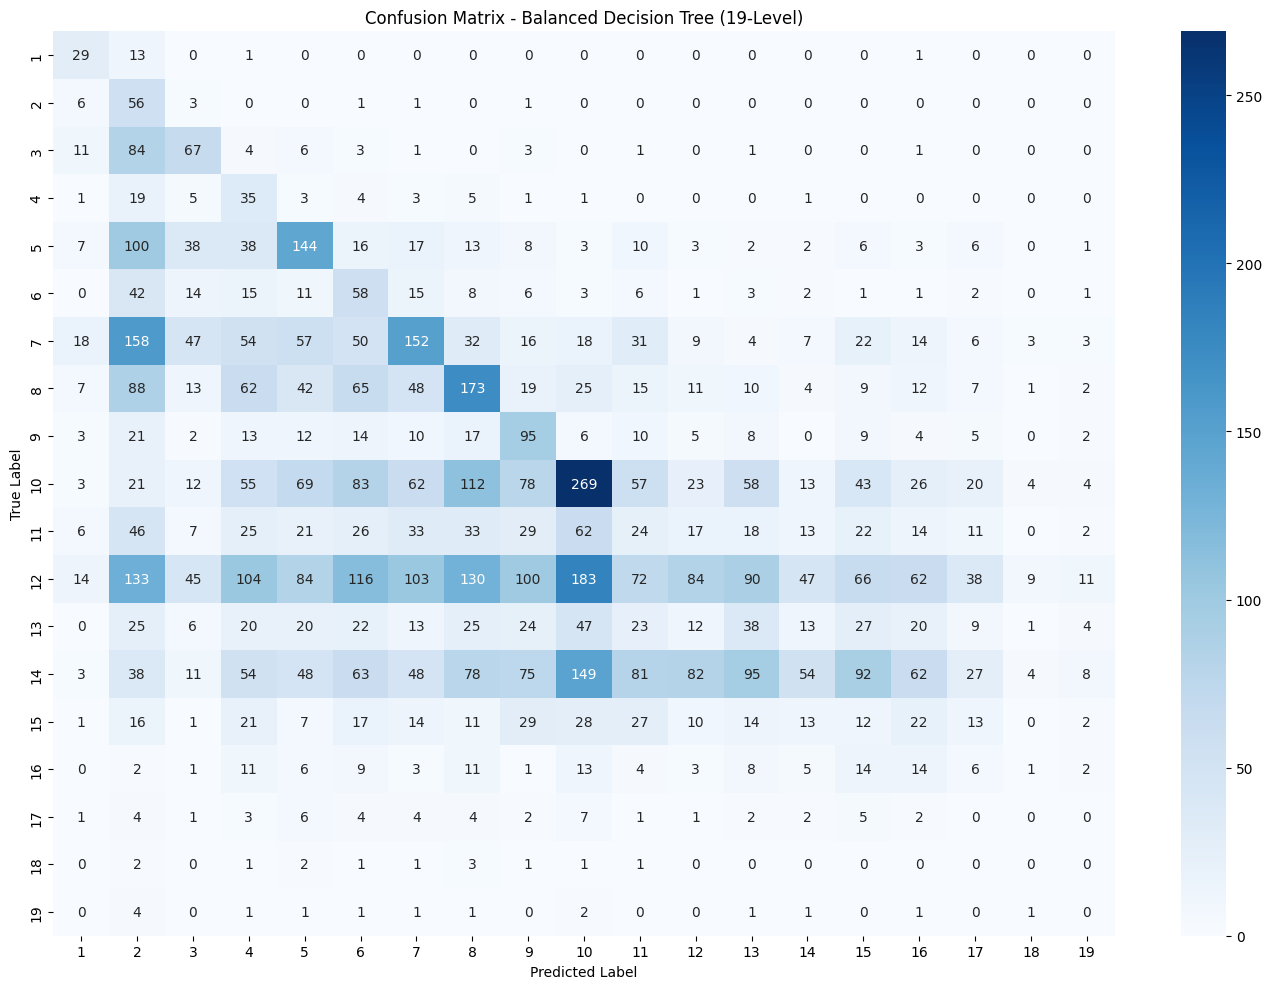

In [61]:

dt_tuned_19_balanced_metrics = evaluate_dt_model(
    dt_y_dev_19,
    dt_tuned_19_balanced_pred,
    "Tuned Decision Tree (19-Level) - Balanced - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_19,
    dt_tuned_19_balanced_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - Balanced Decision Tree (19-Level)"
)



### 4.5 Tuned Decision Tree — No Class Weighting (19-Level)

The best hyperparameters identified by GridSearchCV are used to train a Decision Tree with `class_weight=None`.

This configuration allows comparison with the balanced model while keeping the selected hyperparameters unchanged.


Tuned Decision Tree (19-Level) - None - Dev Set
Accuracy: 0.2744
Adjacent Accuracy (±1): 0.3951
QWK: 0.4235
Macro F1: 0.1971
Weighted Precision: 0.2692
Weighted Recall: 0.2744
MAE: 2.5672
RMSE: 3.5565
R²: -0.1127

Classification Report:

              precision    recall  f1-score   support

           1       0.70      0.48      0.57        44
           2       0.10      0.10      0.10        68
           3       0.26      0.32      0.29       182
           4       0.11      0.28      0.16        78
           5       0.35      0.41      0.38       417
           6       0.21      0.20      0.20       189
           7       0.23      0.49      0.31       701
           8       0.26      0.37      0.31       613
           9       0.44      0.33      0.38       236
          10       0.32      0.49      0.39      1012
          11       0.09      0.06      0.07       409
          12       0.31      0.23      0.26      1491
          13       0.21      0.08      0.12       349
     

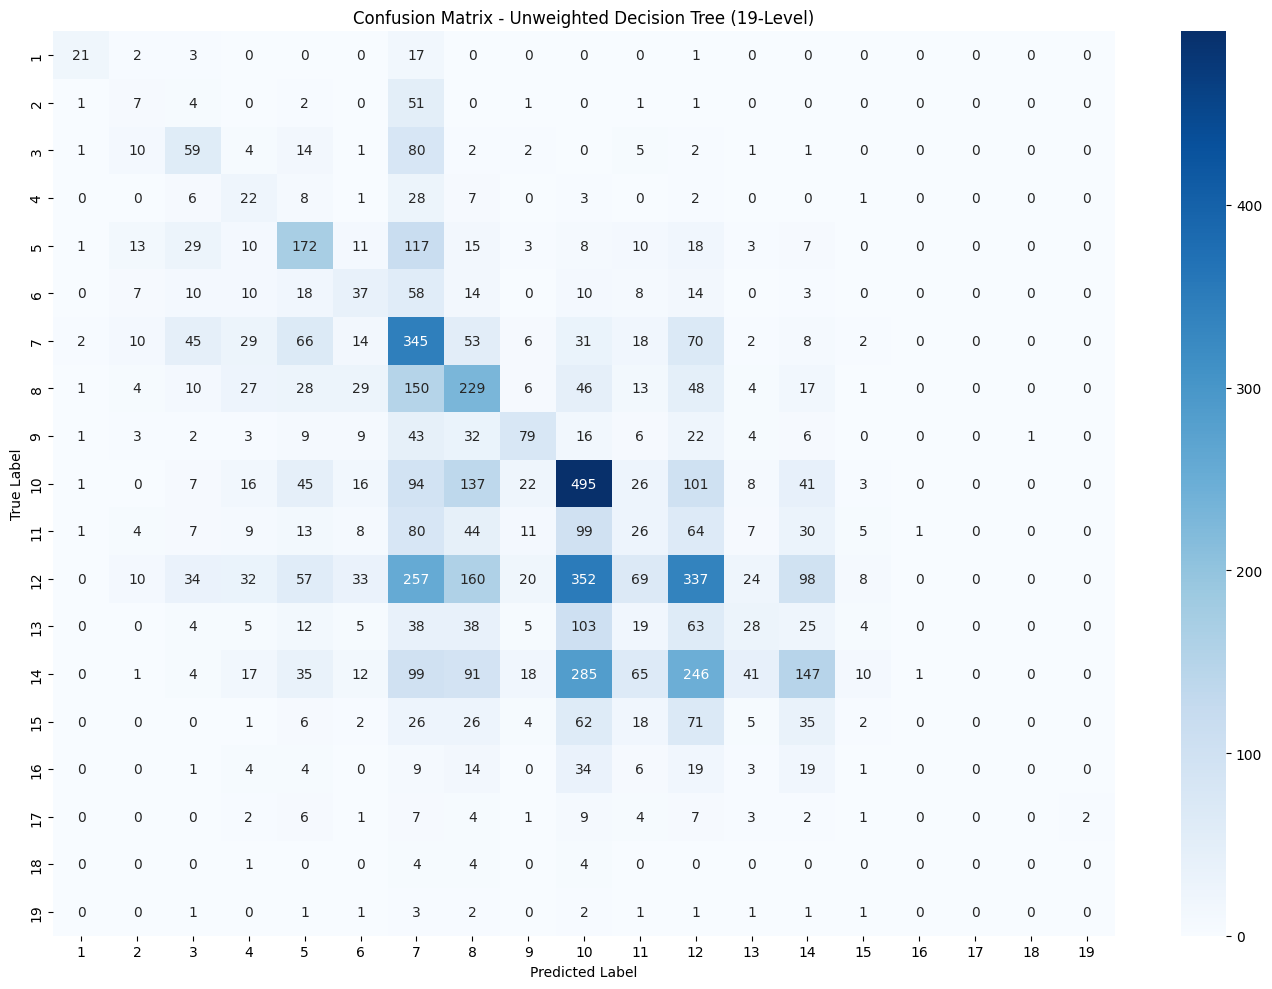

In [62]:

dt_tuned_19_none = DecisionTreeClassifier(
    **dt_grid_19.best_params_,
    class_weight=None,
    random_state=42
)

dt_tuned_19_none.fit(
    dt_X_train_tfidf,
    dt_y_train_19
)

dt_tuned_19_none_pred = dt_tuned_19_none.predict(
    dt_X_dev_tfidf
)

dt_tuned_19_none_metrics = evaluate_dt_model(
    dt_y_dev_19,
    dt_tuned_19_none_pred,
    "Tuned Decision Tree (19-Level) - None - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_19,
    dt_tuned_19_none_pred,
    labels=list(range(1, 20)),
    title="Confusion Matrix - Unweighted Decision Tree (19-Level)"
)



### 4.6 Tuned Decision Tree Findings (19-Level)

The tuned Decision Tree without class weighting achieved an Accuracy of 0.2744 and a Quadratic Weighted Kappa (QWK) of 0.4235 on the development set. Adjacent Accuracy was 0.3951, with a Macro F1-score of 0.1971 and an MAE of 2.5672.


Compared with the baseline, QWK improved from 0.3550 to 0.4235, and MAE decreased from 2.6369 to 2.5672. However, Accuracy decreased from 0.2858 to 0.2744, and Macro F1-score decreased from 0.2207 to 0.1971.


Overall, hyperparameter tuning improved ordinal agreement and reduced prediction error, but did not improve overall classification accuracy. The model continued to struggle with higher readability levels, particularly Levels 16–19.



## **5. Decision Tree (5-Level)**



### 5.1 Decision Tree Baseline (5-Level)

A baseline Decision Tree classifier is trained for the 5-level Arabic readability classification task using the same TF-IDF features and default hyperparameters.

The model is evaluated on the development set to establish a baseline for subsequent hyperparameter tuning.


Default Parameters:
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
Baseline Decision Tree (5-Level) - Dev Set
Accuracy: 0.4326
Adjacent Accuracy (±1): 0.7572
QWK: 0.2982
Macro F1: 0.3289
Weighted Precision: 0.4142
Weighted Recall: 0.4326
MAE: 0.8550
RMSE: 1.2363
R²: -0.2438

Classification Report:

              precision    recall  f1-score   support

           1       0.51      0.61      0.56      1679
           2       0.45      0.60      0.52      2270
           3       0.32      0.30      0.31      1840
           4       0.40      0.17      0.23      1330
           5       0.09      0.02      0.03       191

    accuracy                           0.43      7310
   macro avg       0.35      0.34      0.33      7310
weighted avg 

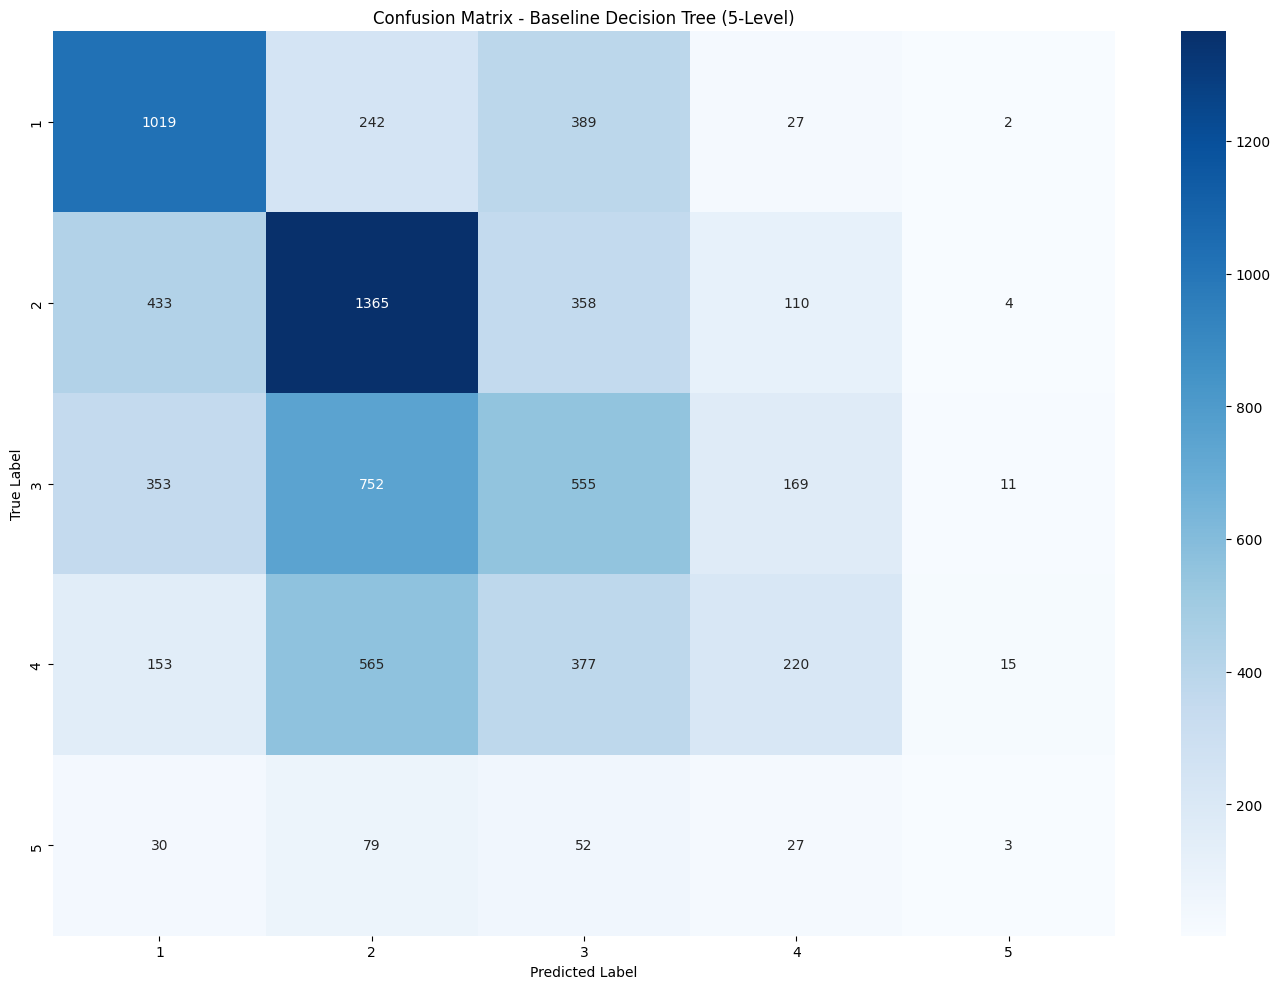

In [63]:

dt_baseline_5 = DecisionTreeClassifier(random_state=42)

print("Default Parameters:")
print(dt_baseline_5.get_params())

dt_baseline_5.fit(
    dt_X_train_tfidf,
    dt_y_train_5
)

dt_baseline_5_dev_pred = dt_baseline_5.predict(
    dt_X_dev_tfidf
)

dt_baseline_5_metrics = evaluate_dt_model(
    dt_y_dev_5,
    dt_baseline_5_dev_pred,
    "Baseline Decision Tree (5-Level) - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_5,
    dt_baseline_5_dev_pred,
    labels=sorted(dt_y_train_5.unique()),
    title="Confusion Matrix - Baseline Decision Tree (5-Level)"
)



### 5.2 Decision Tree Baseline Findings (5-Level)

The baseline Decision Tree achieved an Accuracy of 0.4326 and a Quadratic Weighted Kappa (QWK) of 0.2982 on the development set. Adjacent Accuracy was 0.7572, with a Macro F1-score of 0.3289 and an MAE of 0.8550.


The model performed better on Levels 1 and 2 but struggled with higher readability levels, particularly Level 5, which achieved a recall of only 0.02 and an F1-score of 0.03.


### 5.3 Decision Tree Hyperparameter Tuning Using GridSearchCV (5-Level)

GridSearchCV was used to identify the best combination of hyperparameters for the Decision Tree model. The search focused on `criterion`, `max_depth`, and `min_samples_leaf`, while the remaining parameters were kept at their default values, except for `random_state=42` to ensure reproducibility.

**Hyperparameters and Search Space**

- **Criterion:** Determines how the Decision Tree measures the quality of a split. Both `gini` and `entropy` were tested to compare two different splitting criteria.
- **Max Depth:** Controls the maximum depth of the tree. The values `[None, 15, 30, 50]` were tested to examine different levels of tree complexity and reduce potential overfitting.
- **Min Samples Leaf:** Specifies the minimum number of samples required at a leaf node. The values `[2, 5]` were tested to control the size of leaf nodes and improve generalization.



In [64]:

dt_grid_5, dt_tuning_df_5 = tune_dt_gridsearch(
    dt_y_train_5,
    dt_y_dev_5
)

display(
    dt_tuning_df_5[
        [
            "param_criterion",
            "param_max_depth",
            "param_min_samples_leaf",
            "mean_test_score",
            "rank_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    )
)


Fitting 1 folds for each of 16 candidates, totalling 16 fits
Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 5}
Best Dev QWK: 0.3516
Combinations: 16


,param_criterion,param_max_depth,param_min_samples_leaf,mean_test_score,rank_test_score
1,gini,None,5,0.351560,1
0,gini,None,2,0.340676,2
8,entropy,None,2,0.335564,3
9,entropy,None,5,0.329987,4
7,gini,50,5,0.324116,5
14,entropy,50,2,0.316381,6
6,gini,50,2,0.312406,7
5,gini,30,5,0.307941,8
15,entropy,50,5,0.307703,9
4,gini,30,2,0.300320,10



### 5.4 Tuned Decision Tree — Balanced (5-Level)

The best hyperparameters identified by GridSearchCV are used to train a balanced Decision Tree for the 5-level classification task.

Class weighting is applied to investigate whether accounting for differences in class frequencies improves model performance.


Tuned Decision Tree (5-Level) - Balanced - Dev Set
Accuracy: 0.4220
Adjacent Accuracy (±1): 0.7514
QWK: 0.3768
Macro F1: 0.3407
Weighted Precision: 0.4178
Weighted Recall: 0.4220
MAE: 0.9068
RMSE: 1.3216
R²: -0.4214

Classification Report:

              precision    recall  f1-score   support

           1       0.48      0.80      0.60      1679
           2       0.46      0.45      0.45      2270
           3       0.36      0.20      0.26      1840
           4       0.40      0.23      0.29      1330
           5       0.07      0.16      0.10       191

    accuracy                           0.42      7310
   macro avg       0.35      0.37      0.34      7310
weighted avg       0.42      0.42      0.40      7310



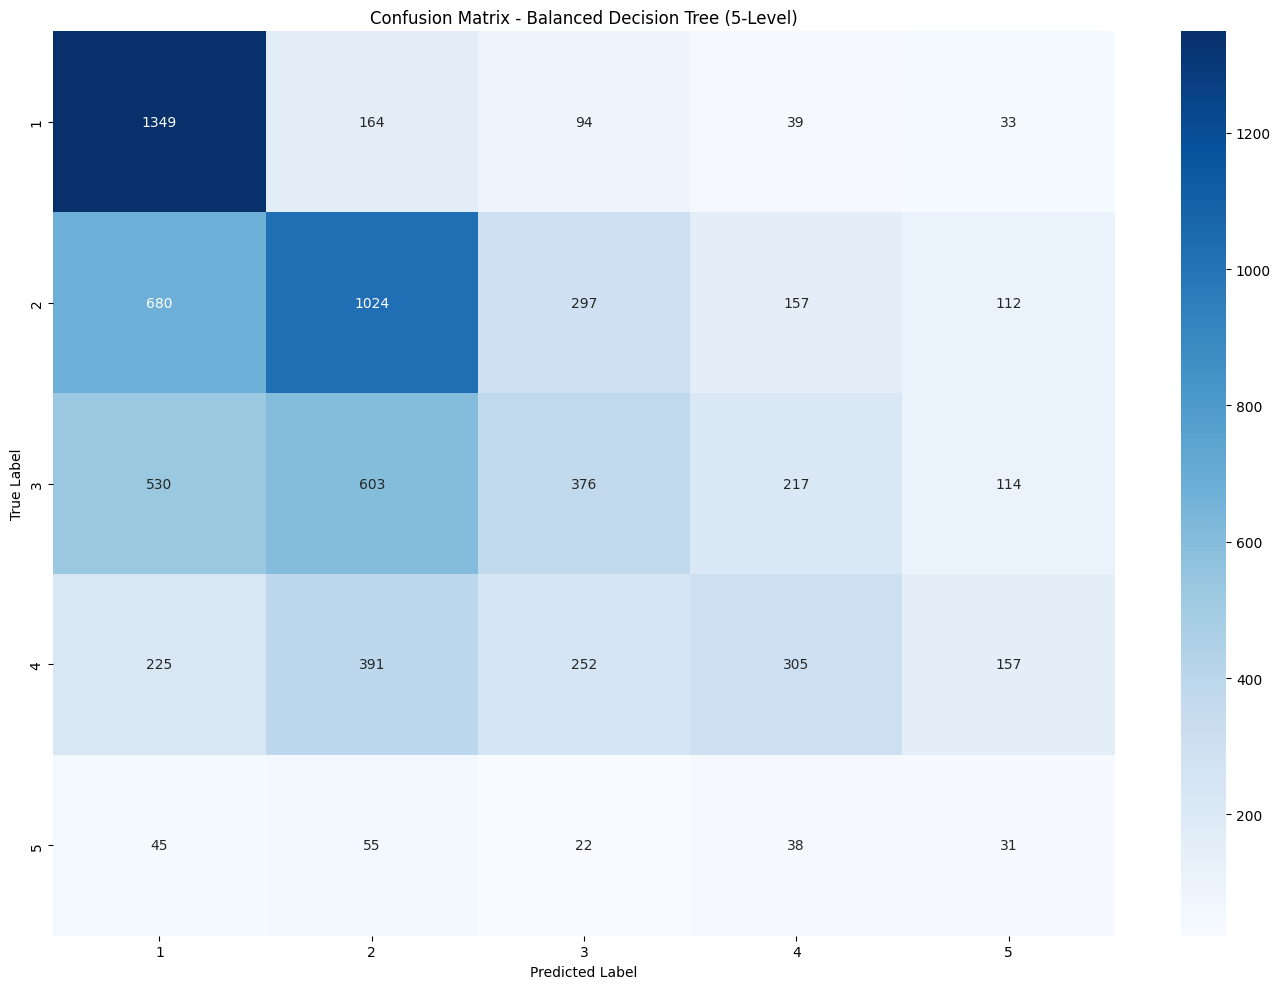

In [65]:

dt_tuned_5_balanced = DecisionTreeClassifier(
    **dt_grid_5.best_params_,
    class_weight="balanced",
    random_state=42
)

dt_tuned_5_balanced.fit(
    dt_X_train_tfidf,
    dt_y_train_5
)

dt_tuned_5_balanced_dev_pred = dt_tuned_5_balanced.predict(
    dt_X_dev_tfidf
)

dt_tuned_5_balanced_metrics = evaluate_dt_model(
    dt_y_dev_5,
    dt_tuned_5_balanced_dev_pred,
    "Tuned Decision Tree (5-Level) - Balanced - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_5,
    dt_tuned_5_balanced_dev_pred,
    labels=sorted(dt_y_train_5.unique()),
    title="Confusion Matrix - Balanced Decision Tree (5-Level)"
)



### 5.5 Tuned Decision Tree — No Class Weighting (5-Level)

The selected hyperparameters are used to train an unweighted Decision Tree for the 5-level classification task.

This configuration is compared with the balanced model to evaluate the effect of class weighting.


Tuned Decision Tree (5-Level) - None - Dev Set
Accuracy: 0.4487
Adjacent Accuracy (±1): 0.7769
QWK: 0.3516
Macro F1: 0.3389
Weighted Precision: 0.4331
Weighted Recall: 0.4487
MAE: 0.8306
RMSE: 1.2304
R²: -0.2320

Classification Report:

              precision    recall  f1-score   support

           1       0.49      0.80      0.61      1679
           2       0.44      0.56      0.49      2270
           3       0.38      0.24      0.29      1840
           4       0.45      0.17      0.24      1330
           5       0.29      0.03      0.06       191

    accuracy                           0.45      7310
   macro avg       0.41      0.36      0.34      7310
weighted avg       0.43      0.45      0.41      7310



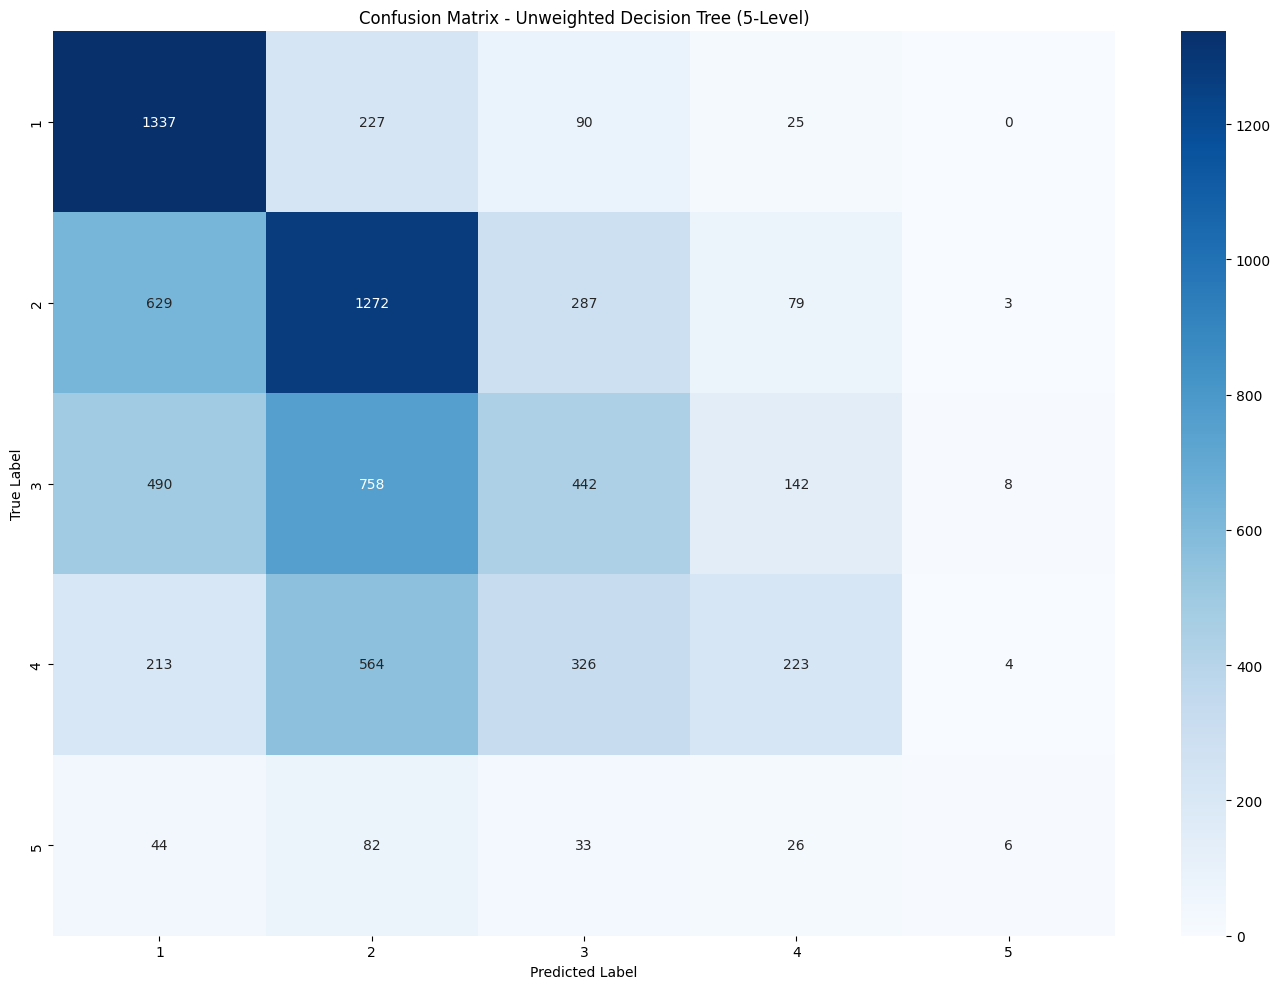

In [66]:

dt_tuned_5_none = DecisionTreeClassifier(
    **dt_grid_5.best_params_,
    class_weight=None,
    random_state=42
)

dt_tuned_5_none.fit(
    dt_X_train_tfidf,
    dt_y_train_5
)

dt_tuned_5_none_dev_pred = dt_tuned_5_none.predict(
    dt_X_dev_tfidf
)

dt_tuned_5_none_metrics = evaluate_dt_model(
    dt_y_dev_5,
    dt_tuned_5_none_dev_pred,
    "Tuned Decision Tree (5-Level) - None - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_5,
    dt_tuned_5_none_dev_pred,
    labels=sorted(dt_y_train_5.unique()),
    title="Confusion Matrix - Unweighted Decision Tree (5-Level)"
)



### 5.6 Decision Tree Tuned Findings (5-Level)

The tuned Decision Tree without class weighting achieved an Accuracy of 0.4487 and a QWK of 0.3516 on the development set. Adjacent Accuracy was 0.7769, with a Macro F1-score of 0.3389 and an MAE of 0.8306.


Compared with the baseline, Accuracy improved from 0.4326 to 0.4487, while QWK increased from 0.2982 to 0.3516. The model performed relatively better on Levels 1 and 2 but continued to struggle with Level 5, which achieved an F1-score of only 0.06.


The balanced model achieved a higher QWK of 0.3768, while the unweighted model achieved higher Accuracy and lower MAE. Therefore, the preferred configuration depends on the evaluation metric, with the balanced model performing better in terms of QWK.


## **6. Decision Tree (4-Level)**



### 6.1 Decision Tree Baseline (4-Level)

A baseline Decision Tree classifier is trained for the 4-level Arabic readability classification task using the existing TF-IDF features and default hyperparameters.

The model is evaluated on the development set to establish a baseline for subsequent hyperparameter tuning.


{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
Baseline Decision Tree (4-Level) - Dev Set
Accuracy: 0.4434
Adjacent Accuracy (±1): 0.7703
QWK: 0.3221
Macro F1: 0.4168
Weighted Precision: 0.4399
Weighted Recall: 0.4434
MAE: 0.8152
RMSE: 1.1790
R²: -0.2392

Classification Report:

              precision    recall  f1-score   support

           1       0.52      0.62      0.56      1679
           2       0.45      0.59      0.51      2270
           3       0.33      0.31      0.32      1840
           4       0.47      0.19      0.27      1521

    accuracy                           0.44      7310
   macro avg       0.44      0.43      0.42      7310
weighted avg       0.44      0.44      0.43      7310



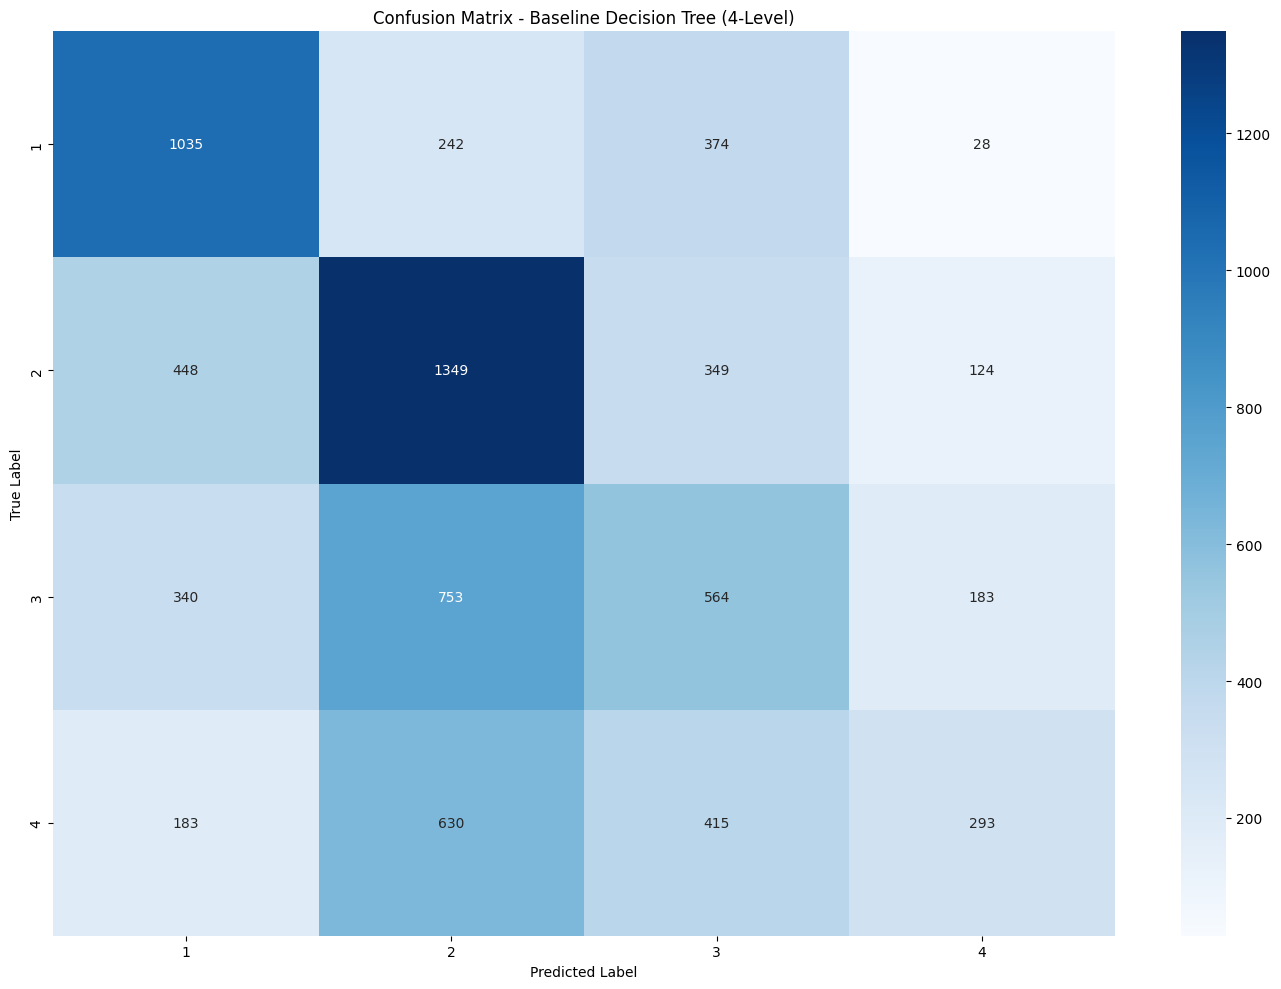

In [67]:

dt_baseline_4 = DecisionTreeClassifier(random_state=42)

print(dt_baseline_4.get_params())

dt_baseline_4.fit(
    dt_X_train_tfidf,
    dt_y_train_4
)

dt_baseline_4_dev_pred = dt_baseline_4.predict(
    dt_X_dev_tfidf
)

dt_baseline_4_metrics = evaluate_dt_model(
    dt_y_dev_4,
    dt_baseline_4_dev_pred,
    "Baseline Decision Tree (4-Level) - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_4,
    dt_baseline_4_dev_pred,
    labels=sorted(dt_y_train_4.unique()),
    title="Confusion Matrix - Baseline Decision Tree (4-Level)"
)



### 6.2 Decision Tree Baseline Findings (4-Level)

The baseline Decision Tree achieved an Accuracy of 0.4434 and a QWK of 0.3221 on the development set. Adjacent Accuracy was 0.7703, with a Macro F1-score of 0.4168 and an MAE of 0.8152.


The model performed relatively better on Levels 1 and 2, achieving F1-scores of 0.56 and 0.51, respectively. However, it struggled with Level 4, which achieved a recall of only 0.19 and an F1-score of 0.27.
These results establish the baseline performance for comparison with the tuned Decision Tree models.


### 6.3 Decision Tree Hyperparameter Tuning Using GridSearchCV (4-Level)

GridSearchCV was used to identify the best combination of hyperparameters for the Decision Tree model. The search focused on `criterion`, `max_depth`, and `min_samples_leaf`, while the remaining parameters were kept at their default values, except for `random_state=42` to ensure reproducibility.

**Hyperparameters and Search Space**

- **Criterion:** Determines how the Decision Tree measures the quality of a split. Both `gini` and `entropy` were tested to compare two different splitting criteria.
- **Max Depth:** Controls the maximum depth of the tree. The values `[None, 15, 30, 50]` were tested to examine different levels of tree complexity and reduce potential overfitting.
- **Min Samples Leaf:** Specifies the minimum number of samples required at a leaf node. The values `[2, 5]` were tested to control the size of leaf nodes and improve generalization.



In [68]:

dt_grid_4, dt_tuning_df_4 = tune_dt_gridsearch(
    dt_y_train_4,
    dt_y_dev_4
)

display(
    dt_tuning_df_4[
        [
            "param_criterion",
            "param_max_depth",
            "param_min_samples_leaf",
            "mean_test_score",
            "rank_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    )
)


Fitting 1 folds for each of 16 candidates, totalling 16 fits
Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 5}
Best Dev QWK: 0.3662
Combinations: 16


,param_criterion,param_max_depth,param_min_samples_leaf,mean_test_score,rank_test_score
1,gini,None,5,0.366247,1
0,gini,None,2,0.363701,2
8,entropy,None,2,0.353844,3
9,entropy,None,5,0.351846,4
7,gini,50,5,0.343693,5
15,entropy,50,5,0.337321,6
6,gini,50,2,0.334029,7
14,entropy,50,2,0.333765,8
5,gini,30,5,0.327271,9
4,gini,30,2,0.314503,10



### 6.4 Tuned Decision Tree — Balanced (4-Level)

The best hyperparameters identified by GridSearchCV are used to train a balanced Decision Tree for the 4-level classification task.

The model is evaluated on the development set to examine the effect of class weighting.


Tuned Decision Tree (4-Level) - Balanced - Dev Set
Accuracy: 0.4488
Adjacent Accuracy (±1): 0.7785
QWK: 0.3781
Macro F1: 0.4163
Weighted Precision: 0.4341
Weighted Recall: 0.4488
MAE: 0.8168
RMSE: 1.1986
R²: -0.2807

Classification Report:

              precision    recall  f1-score   support

           1       0.48      0.82      0.61      1679
           2       0.46      0.50      0.48      2270
           3       0.36      0.23      0.28      1840
           4       0.44      0.23      0.30      1521

    accuracy                           0.45      7310
   macro avg       0.43      0.44      0.42      7310
weighted avg       0.43      0.45      0.42      7310



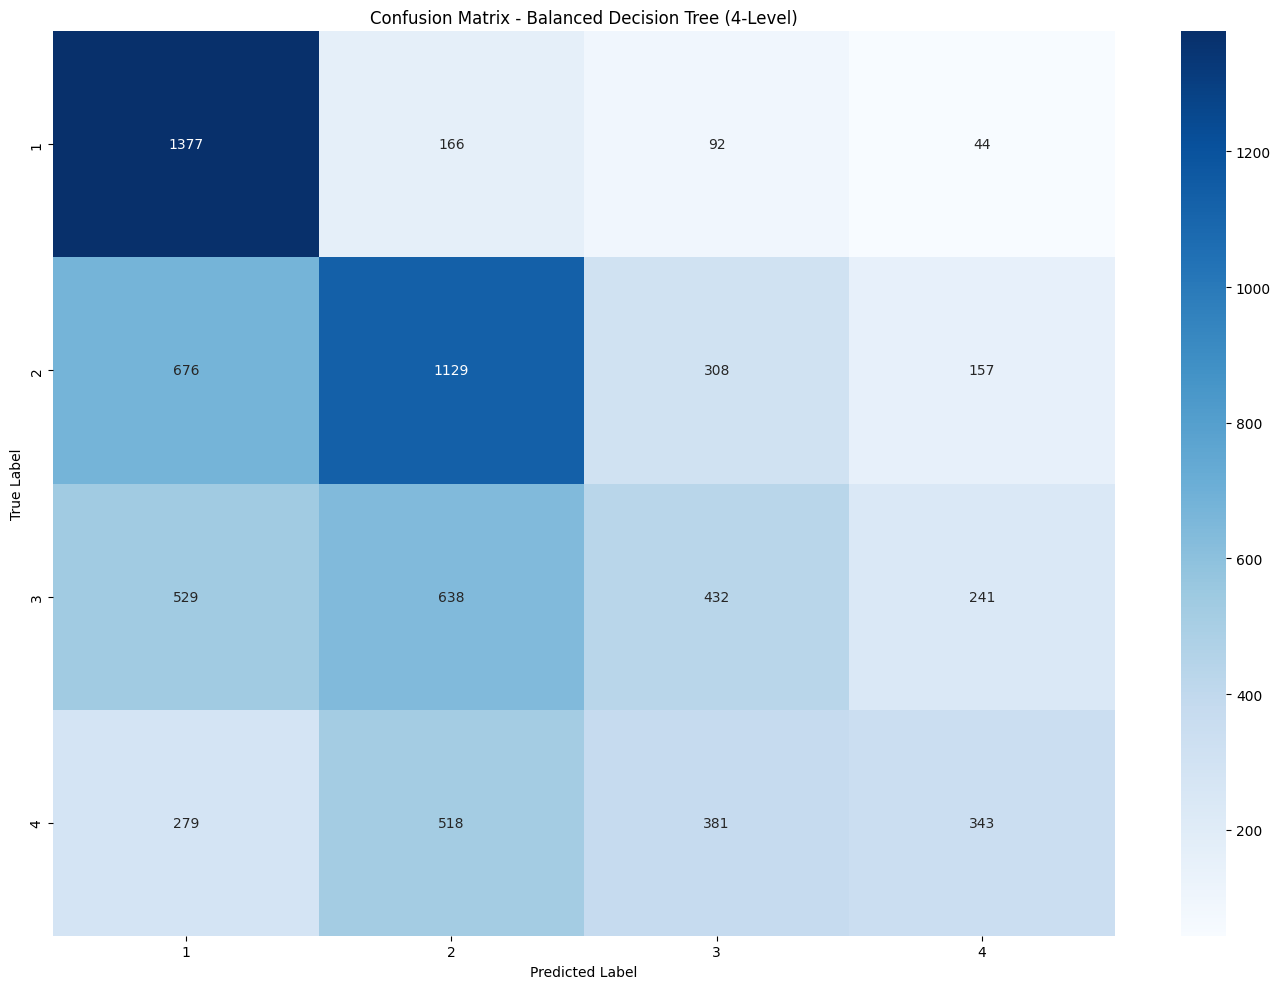

In [69]:

dt_tuned_4_balanced = DecisionTreeClassifier(
    **dt_grid_4.best_params_,
    class_weight="balanced",
    random_state=42
)

dt_tuned_4_balanced.fit(
    dt_X_train_tfidf,
    dt_y_train_4
)

dt_tuned_4_balanced_dev_pred = dt_tuned_4_balanced.predict(
    dt_X_dev_tfidf
)

dt_tuned_4_balanced_metrics = evaluate_dt_model(
    dt_y_dev_4,
    dt_tuned_4_balanced_dev_pred,
    "Tuned Decision Tree (4-Level) - Balanced - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_4,
    dt_tuned_4_balanced_dev_pred,
    labels=sorted(dt_y_train_4.unique()),
    title="Confusion Matrix - Balanced Decision Tree (4-Level)"
)



### 6.5 Tuned Decision Tree — No Class Weighting (4-Level)

The selected hyperparameters are used to train an unweighted Decision Tree for the 4-level classification task.

This configuration is evaluated using the same development set to compare its performance with the balanced model.


Tuned Decision Tree (4-Level) - None - Dev Set
Accuracy: 0.4577
Adjacent Accuracy (±1): 0.7814
QWK: 0.3662
Macro F1: 0.4185
Weighted Precision: 0.4488
Weighted Recall: 0.4577
MAE: 0.7990
RMSE: 1.1785
R²: -0.2382

Classification Report:

              precision    recall  f1-score   support

           1       0.50      0.79      0.61      1679
           2       0.44      0.56      0.50      2270
           3       0.39      0.25      0.31      1840
           4       0.47      0.18      0.26      1521

    accuracy                           0.46      7310
   macro avg       0.45      0.45      0.42      7310
weighted avg       0.45      0.46      0.43      7310



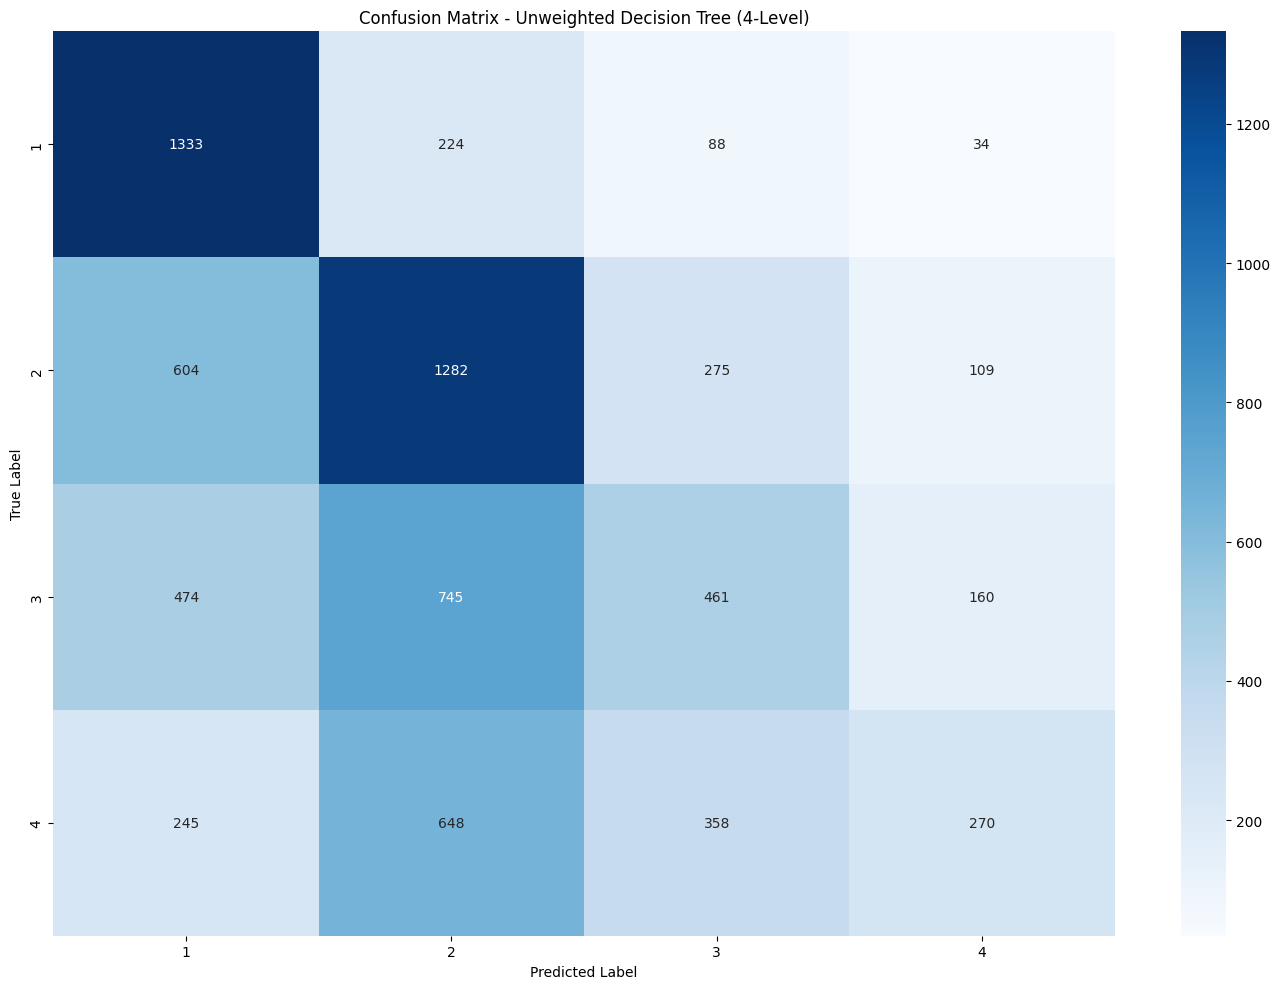

In [70]:

dt_tuned_4_none = DecisionTreeClassifier(
    **dt_grid_4.best_params_,
    class_weight=None,
    random_state=42
)

dt_tuned_4_none.fit(
    dt_X_train_tfidf,
    dt_y_train_4
)

dt_tuned_4_none_dev_pred = dt_tuned_4_none.predict(
    dt_X_dev_tfidf
)

dt_tuned_4_none_metrics = evaluate_dt_model(
    dt_y_dev_4,
    dt_tuned_4_none_dev_pred,
    "Tuned Decision Tree (4-Level) - None - Dev Set"
)

plot_dt_confusion_matrix(
    dt_y_dev_4,
    dt_tuned_4_none_dev_pred,
    labels=sorted(dt_y_train_4.unique()),
    title="Confusion Matrix - Unweighted Decision Tree (4-Level)"
)



### 6.6 Decision Tree Tuned Findings (4-Level)

The tuned Decision Tree without class weighting achieved an Accuracy of 0.4577 and a Quadratic Weighted Kappa (QWK) of 0.3662 on the development set. Adjacent Accuracy was 0.7814, with a Macro F1-score of 0.4185 and an MAE of 0.7990.


The model performed relatively better on Levels 1 and 2, achieving F1-scores of 0.61 and 0.50, respectively. However, it struggled with Levels 3 and 4, particularly Level 4, which achieved a recall of only 0.18.


The balanced model achieved a higher QWK (0.3781) than the unweighted model (0.3662). However, the unweighted model achieved higher Accuracy (0.4577 vs. 0.4488), a slightly higher Macro F1-score (0.4185 vs. 0.4163), and a lower MAE (0.7990 vs. 0.8168). Therefore, the balanced model performed better in terms of QWK, while the unweighted model performed better on the other main evaluation metrics.


## **7. Final Decision Tree Experimental Comparison**



### 7.1 Overall Performance Comparison

The baseline and tuned Decision Tree models were evaluated on the development set across the 19-level, 5-level, and 4-level readability classification tasks.


Quadratic Weighted Kappa (QWK) was used as the scoring metric for hyperparameter selection.


| Classification Level | Model | Accuracy | Adjacent Accuracy (±1) | QWK | Macro F1 | Weighted Precision | Weighted Recall | MAE | RMSE | R² |
|---|---|---|---|---|---|---|---|---|---|---|
| 19-Level | Baseline | 0.2858 | 0.4140 | 0.3550 | 0.2207 | 0.2938 | 0.2858 | 2.6369 | 3.7483 | -0.2359 |
| 19-Level | Tuned - Balanced | 0.1784 | 0.3174 | 0.3551 | 0.1532 | 0.2499 | 0.1784 | 3.5860 | 4.7538 | -0.9880 |
| 19-Level | Tuned - None | 0.2744 | 0.3951 | 0.4235 | 0.1971 | 0.2692 | 0.2744 | 2.5672 | 3.5565 | -0.1127 |
| 5-Level | Baseline | 0.4326 | 0.7572 | 0.2982 | 0.3289 | 0.4142 | 0.4326 | 0.8550 | 1.2363 | -0.2438 |
| 5-Level | Tuned - Balanced | 0.4220 | 0.7514 | 0.3768 | 0.3407 | 0.4178 | 0.4220 | 0.9068 | 1.3216 | -0.4214 |
| 5-Level | Tuned - None | 0.4487 | 0.7769 | 0.3516 | 0.3389 | 0.4331 | 0.4487 | 0.8306 | 1.2304 | -0.2320 |
| 4-Level | Baseline | 0.4434 | 0.7703 | 0.3221 | 0.4168 | 0.4399 | 0.4434 | 0.8152 | 1.1790 | -0.2392 |
| 4-Level | Tuned - Balanced | 0.4488 | 0.7785 | 0.3781 | 0.4163 | 0.4341 | 0.4488 | 0.8168 | 1.1986 | -0.2807 |
| 4-Level | Tuned - None | 0.4577 | 0.7814 | 0.3662 | 0.4185 | 0.4488 | 0.4577 | 0.7990 | 1.1785 | -0.2382 |




### 7.2 Hyperparameter Tuning Results

GridSearchCV selected the following Decision Tree hyperparameters based on development-set QWK.



| Classification Level | Criterion | Max Depth | Min Samples Leaf | Best Dev QWK |
|---|---|---|---|---|
| 19-Level | gini | None | 5 | 0.4235 |
| 5-Level | gini | None | 5 | 0.3516 |
| 4-Level | gini | None | 5 | 0.3662 |


GridSearchCV evaluated 16 hyperparameter combinations for each classification task using QWK and `class_weight=None`. The selected hyperparameters were then used to train both balanced and unweighted Decision Tree models. Therefore, the Best Dev QWK values represent the unweighted configurations evaluated during hyperparameter tuning.

### 7.3 Analysis of Experimental Results

The experimental results show that reducing the number of readability levels generally improved Accuracy and Macro F1-score. The 4-level classification achieved the highest Accuracy (0.4577) and Macro F1-score (0.4185). The highest QWK value (0.4235) was obtained in the 19-level task, although QWK values across different classification levels should be interpreted with caution.

Hyperparameter tuning improved QWK compared with the baseline across all three tasks. Class weighting further improved QWK for the 5-level and 4-level tuned models, but the unweighted models achieved higher Accuracy and lower MAE. For the 19-level task, class weighting reduced Accuracy and Macro F1-score without a meaningful improvement in QWK compared with the baseline.

Overall, hyperparameter tuning improved ordinal agreement, but neither tuning nor class weighting consistently improved every metric. The results demonstrate the trade-off between QWK, Accuracy, and prediction error when selecting a Decision Tree configuration.

### 7.4 Comparison with the BAREC Paper

The BAREC paper reports the following Decision Tree results for the 19-level readability classification task.

The table compares the published Word-based Decision Tree results with our baseline Decision Tree model using Word + TF-IDF features.


| Input Representation | Accuracy (Acc19) | Adjacent Accuracy (±1) | Distance/MAE | QWK |
|---|---:|---:|---:|---:|
| BAREC Paper - Word | 0.2720 | 0.4120 | 2.5000 | 0.4420 |
| Our Word + TF-IDF Baseline | 0.2858 | 0.4140 | 2.6369 | 0.3550 |


**Comparison Findings**

The Decision Tree baseline was compared with the Word-based Decision Tree results reported in the BAREC paper.

The published Decision Tree achieved 27.2% Accuracy, 41.2% Adjacent Accuracy, a Distance of 2.50, and a QWK of 0.442.

Our Decision Tree baseline achieved **28.58% Accuracy**, **41.40% Adjacent Accuracy**, an **MAE of 2.6369**, and a **QWK of 0.3550**.

Our Decision Tree baseline achieved slightly higher Accuracy (0.2858 vs. 0.2720) and Adjacent Accuracy (0.4140 vs. 0.4120) than the published Word-based Decision Tree. However, the published model achieved a higher QWK (0.4420 vs. 0.3550), indicating stronger ordinal agreement. The paper reported a Distance of 2.50, while our model achieved an MAE of 2.6369; these error values should be compared cautiously unless their calculation methods are confirmed to be equivalent.